# 01 · Carga, limpieza y validación de datos — Foodie-Fi

**Proyecto:** Análisis de clientes de un servicio de suscripción (cohortes, retención, churn y segmentación)
**Etapa:** 1 de 5 · Preparación de datos
**Fuente:** Foodie-Fi — *8-Week SQL Challenge, Case Study #3* (dataset **sintético**; ver `data/README.md`)

## Objetivo de este notebook
Dejar los datos **confiables y listos para analizar**. Al terminar tendremos:

1. Los archivos originales cargados sin alterarse (se verifica con hashes).
2. Un diagnóstico de calidad documentado: nulos, duplicados, fechas, relaciones entre tablas y reglas de negocio.
3. Dos datasets limpios y consolidados en `data/processed/`:
   - `foodie_fi_events_clean.csv` → una fila por **evento de suscripción** (2.650 filas).
   - `foodie_fi_customers_clean.csv` → una fila por **cliente** (1.000 filas), base de los notebooks 02–05.

## Contexto del negocio
Foodie-Fi vende suscripciones de streaming de videos de cocina. Cada cliente comienza con un **trial de 7 días** y luego elige un plan
(*basic monthly*, *pro monthly* o *pro annual*) o cancela (*churn*). La tabla `subscriptions` registra **la fecha en que empieza cada plan**,
no una fila por mes de facturación.

## Principios de trabajo
- **Los datos originales (`data/raw/`) no se modifican.** Todo se hace sobre copias en memoria.
- Cada decisión de limpieza se justifica y queda en un **registro de transformaciones** (sección 9).
- Toda cifra relevante se valida con un **chequeo independiente** (asserts) o contra valores publicados.

## Índice
1. Importación de librerías y configuración
2. Carga de los archivos originales
3. Inspección inicial
4. Dimensiones, tipos y valores únicos
5. Nulos y duplicados
6. Conversión y validación de fechas
7. Validación de relaciones entre tablas
8. Detección de inconsistencias (reglas de negocio)
9. Limpieza y preparación
10. Dataset consolidado
11. Guardado y verificación de lectura
12. Verificación de integridad y conclusiones

## 1. Importación de librerías y configuración

In [1]:
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 150)

# Raíz del proyecto: funciona ejecutando el notebook desde notebooks/ o desde la raíz del repo
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROC_DIR = PROJECT_ROOT / "data" / "processed"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
for d in (PROC_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(f"pandas {pd.__version__} | numpy {np.__version__}")
print("Carpeta de datos originales:", RAW_DIR.relative_to(PROJECT_ROOT))

pandas 3.0.6 | numpy 2.5.4
Carpeta de datos originales: data/raw


### Huella digital de los datos originales
Antes de tocar nada calculo el hash SHA-256 de cada archivo original. Al final del notebook (sección 12) lo recalculo:
si coinciden, queda **demostrado** que los originales no se modificaron.

In [2]:
def sha256(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()

raw_files = sorted(RAW_DIR.glob("*.csv"))
raw_hashes_before = {p.name: sha256(p) for p in raw_files}
for name, h in raw_hashes_before.items():
    print(f"{name:20s} sha256 = {h[:20]}…")

plans.csv            sha256 = 49b2f208e9135632895b…
subscriptions.csv    sha256 = 142a002083b29ace5a7b…


## 2. Carga de los archivos originales

Dos tablas:

| Tabla | Contenido |
|---|---|
| `plans` | Catálogo de planes: `plan_id`, `plan_name`, `price` |
| `subscriptions` | Eventos: `customer_id`, `plan_id`, `start_date` (fecha de inicio del plan) |

**Cuidado con los problemas de importación** (el proyecto exige detectarlos explícitamente):

- **Separador decimal:** los precios usan *punto* (`9.90`). Si algún día el archivo llegara con coma (`9,90`), `read_csv` lo leería como texto sin avisar.
- **Formato de fecha:** el origen es ISO `YYYY-MM-DD`. Se parsea con **formato explícito** para que nunca se confunda día/mes.

Estrategia en dos pasos: primero una lectura **100 % texto** (para ver exactamente lo que hay en el archivo) y luego la lectura **tipada**.

In [3]:
# 2.1 Lectura "cruda": todo como texto y sin convertir vacíos a NaN → vemos el archivo tal cual está
plans_raw = pd.read_csv(RAW_DIR / "plans.csv", dtype=str, keep_default_na=False)
subs_raw = pd.read_csv(RAW_DIR / "subscriptions.csv", dtype=str, keep_default_na=False)

# 2.2 Chequeos de FORMATO sobre el texto original
assert subs_raw["customer_id"].str.fullmatch(r"\d+").all(), "customer_id con caracteres no numéricos"
assert subs_raw["plan_id"].str.fullmatch(r"\d+").all(), "plan_id con caracteres no numéricos"
assert subs_raw["start_date"].str.fullmatch(r"\d{4}-\d{2}-\d{2}").all(), "Hay fechas que no son YYYY-MM-DD"
assert plans_raw["price"].str.fullmatch(r"(\d+(\.\d+)?)?").all(), "price con formato inesperado"
assert not plans_raw["price"].str.contains(",").any(), "price usa coma decimal"
print("✔ Formatos de origen correctos: fechas ISO y precios con punto decimal (o vacío).")

plans_raw

✔ Formatos de origen correctos: fechas ISO y precios con punto decimal (o vacío).


,plan_id,plan_name,price
0,0,trial,0
1,1,basic monthly,9.90
2,2,pro monthly,19.90
3,3,pro annual,199
4,4,churn,


In [4]:
# 2.3 Lectura TIPADA: tipos explícitos y parseo de fechas con formato fijo (errors="raise" → falla fuerte si algo no cuadra)
plans = pd.read_csv(
    RAW_DIR / "plans.csv",
    dtype={"plan_id": "int64", "plan_name": "string", "price": "float64"},
    decimal=".",
)
subs = pd.read_csv(RAW_DIR / "subscriptions.csv", dtype={"customer_id": "int64", "plan_id": "int64"})
subs["start_date"] = pd.to_datetime(subs["start_date"], format="%Y-%m-%d", errors="raise")

print("plans:", plans.shape, "| subscriptions:", subs.shape)

plans: (5, 3) | subscriptions: (2650, 3)


## 3. Inspección inicial

In [5]:
print("— plans —")
display(plans)
print("\n— subscriptions (primeras 8 filas) —")
display(subs.head(8))

— plans —


,plan_id,plan_name,price
0,0,trial,0.0
1,1,basic monthly,9.9
2,2,pro monthly,19.9
3,3,pro annual,199.0
4,4,churn,NaN



— subscriptions (primeras 8 filas) —


,customer_id,plan_id,start_date
0,1,0,2020-08-01
1,1,1,2020-08-08
2,2,0,2020-09-20
3,2,3,2020-09-27
4,3,0,2020-01-13
5,3,1,2020-01-20
6,4,0,2020-01-17
7,4,1,2020-01-24


In [6]:
print("— subscriptions.info() —")
subs.info()
print("\n— plans.info() —")
plans.info()

— subscriptions.info() —
<class 'pandas.DataFrame'>
RangeIndex: 2650 entries, 0 to 2649
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   customer_id  2650 non-null   int64         
 1   plan_id      2650 non-null   int64         
 2   start_date   2650 non-null   datetime64[us]
dtypes: datetime64[us](1), int64(2)
memory usage: 62.2 KB

— plans.info() —
<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   plan_id    5 non-null      int64  
 1   plan_name  5 non-null      string 
 2   price      4 non-null      float64
dtypes: float64(1), int64(1), string(1)
memory usage: 252.0 bytes


**Lectura rápida:** `subscriptions` es una tabla de eventos (varias filas por cliente) y `plans` un catálogo de 5 filas.
El `price` del plan *churn* aparece vacío; lo analizo en la sección 5.

## 4. Dimensiones, tipos de datos y valores únicos

In [7]:
def profile(df: pd.DataFrame) -> pd.DataFrame:
    # Resumen de calidad por columna
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "no_nulos": df.notna().sum(),
        "nulos": df.isna().sum(),
        "únicos": df.nunique(),
        "mín": {c: df[c].min() for c in df.columns},
        "máx": {c: df[c].max() for c in df.columns},
    })

print(f"subscriptions → {subs.shape[0]:,} filas × {subs.shape[1]} columnas")
display(profile(subs))
print(f"\nplans → {plans.shape[0]} filas × {plans.shape[1]} columnas")
display(profile(plans))

subscriptions → 2,650 filas × 3 columnas


,dtype,no_nulos,nulos,únicos,mín,máx
customer_id,int64,2650,0,1000,1,1000
plan_id,int64,2650,0,5,0,4
start_date,datetime64[us],2650,0,459,2020-01-01 00:00:00,2021-04-30 00:00:00



plans → 5 filas × 3 columnas


,dtype,no_nulos,nulos,únicos,mín,máx
plan_id,int64,5,0,5,0,4
plan_name,string,5,0,5,basic monthly,trial
price,float64,4,1,4,0.0,199.0


In [8]:
# Eventos por plan (con nombre) y eventos por cliente
events_by_plan = (
    subs.merge(plans[["plan_id", "plan_name"]], on="plan_id", how="left")
        .groupby(["plan_id", "plan_name"]).size().rename("eventos").reset_index()
)
display(events_by_plan)

events_per_customer = subs.groupby("customer_id").size()
print("\nEventos por cliente (cantidad de clientes):")
display(events_per_customer.value_counts().sort_index().rename_axis("eventos").rename("clientes").to_frame().T)

# Los IDs de cliente deberían ser 1..1000 sin huecos
assert sorted(subs["customer_id"].unique()) == list(range(1, 1001)), "IDs de cliente no contiguos"
print("✔ customer_id: 1.000 clientes, IDs contiguos de 1 a 1000.")

,plan_id,plan_name,eventos
0,0,trial,1000
1,1,basic monthly,546
2,2,pro monthly,539
3,3,pro annual,258
4,4,churn,307



Eventos por cliente (cantidad de clientes):


eventos,2,3,4
clientes,430,490,80


✔ customer_id: 1.000 clientes, IDs contiguos de 1 a 1000.


## 5. Detección de nulos y duplicados

In [9]:
print("Nulos en subscriptions:", subs.isna().sum().to_dict())
print("Nulos en plans:        ", plans.isna().sum().to_dict())

# `subscriptions` no debe tener ningún nulo
assert subs.isna().sum().sum() == 0

# El único nulo permitido: price del plan 'churn' (cancelar no es un plan con precio)
null_price_plans = plans.loc[plans["price"].isna(), "plan_name"].tolist()
assert null_price_plans == ["churn"], null_price_plans
print("✔ Único nulo: price del plan 'churn' → es un nulo ESTRUCTURAL (cancelar no tiene precio), no un dato faltante.")

Nulos en subscriptions: {'customer_id': 0, 'plan_id': 0, 'start_date': 0}
Nulos en plans:         {'plan_id': 0, 'plan_name': 0, 'price': 1}
✔ Único nulo: price del plan 'churn' → es un nulo ESTRUCTURAL (cancelar no tiene precio), no un dato faltante.


In [10]:
# Duplicados en tres niveles de exigencia
dups = {
    "fila completa repetida": int(subs.duplicated().sum()),
    "mismo cliente y misma fecha": int(subs.duplicated(["customer_id", "start_date"]).sum()),
    "mismo cliente y mismo plan": int(subs.duplicated(["customer_id", "plan_id"]).sum()),
}
display(pd.Series(dups, name="duplicados").to_frame())
assert all(v == 0 for v in dups.values())
print("✔ Sin duplicados en ninguno de los tres niveles.")

,duplicados
fila completa repetida,0
mismo cliente y misma fecha,0
mismo cliente y mismo plan,0


✔ Sin duplicados en ninguno de los tres niveles.


### Decisión · nulo estructural de `price`
| Opción | Evaluación |
|---|---|
| Eliminar la fila del plan *churn* | ❌ Perderíamos el evento de cancelación. |
| Dejar `NaN` | ⚠️ Cualquier suma de ingresos propagaría `NaN` si no se maneja. |
| **Imputar `0.0` en el dataset consolidado y agregar `is_paid_plan`** | ✅ Cancelar no genera ingreso; el flag permite distinguir un plan gratuito (*trial*) de uno pago sin ambigüedad. |

El catálogo original `plans` **no se modifica**: la imputación se hace sólo en el dataset consolidado.

## 6. Conversión y validación de fechas

In [11]:
# 6.1 Sin fechas inválidas (con errors="raise" ya habría fallado, lo dejamos explícito)
assert subs["start_date"].notna().all()

# 6.2 Verificación de que NO se intercambió día y mes:
#     reconvertir a texto ISO y comparar contra el texto original, fila por fila
roundtrip_ok = subs["start_date"].dt.strftime("%Y-%m-%d").eq(subs_raw["start_date"]).all()
assert roundtrip_ok
# Además existen días > 12, lo que habría delatado una confusión día/mes
assert (subs["start_date"].dt.day > 12).any()
print("✔ Parseo de fechas verificado (ida y vuelta idéntica al texto original).")

# 6.3 Rango temporal
FIRST_DATE, LAST_DATE = subs["start_date"].min(), subs["start_date"].max()
print(f"Rango de fechas: {FIRST_DATE.date()} → {LAST_DATE.date()}  ({(LAST_DATE - FIRST_DATE).days} días)")
assert FIRST_DATE >= pd.Timestamp("2020-01-01") and LAST_DATE <= pd.Timestamp("2021-04-30")

✔ Parseo de fechas verificado (ida y vuelta idéntica al texto original).
Rango de fechas: 2020-01-01 → 2021-04-30  (485 días)


### Supuesto clave · fecha de corte de observación
El dataset **no declara** una fecha de extracción. Asumo como **fecha de corte (`OBSERVATION_END`) la fecha más reciente registrada**.
Es necesario para calcular la duración de los planes aún vigentes y para saber qué clientes están **censurados**
(siguen activos, así que no sabemos cuándo —ni si— van a cancelar).

In [12]:
OBSERVATION_END = LAST_DATE
print("OBSERVATION_END =", OBSERVATION_END.date())

# Fecha de inicio de trial por mes (esto definirá las cohortes más adelante)
trial_id = plans.loc[plans["plan_name"] == "trial", "plan_id"].item()
trial_starts = subs.loc[subs["plan_id"] == trial_id, "start_date"]
print(f"Trials iniciados entre {trial_starts.min().date()} y {trial_starts.max().date()} "
      f"→ {trial_starts.dt.to_period('M').nunique()} meses calendario")

OBSERVATION_END = 2021-04-30
Trials iniciados entre 2020-01-01 y 2020-12-30 → 12 meses calendario


## 7. Validación de relaciones entre tablas

In [13]:
# 7.1 Integridad referencial: todo plan_id de subscriptions existe en plans
orphans = ~subs["plan_id"].isin(plans["plan_id"])
assert orphans.sum() == 0
print("✔ Sin huérfanos: todos los plan_id de subscriptions existen en plans.")

# 7.2 Unicidad de la clave del catálogo
assert plans["plan_id"].is_unique and plans["plan_name"].is_unique
print("✔ plans: plan_id y plan_name únicos.")

# 7.3 ¿Hay planes del catálogo que nunca se usan?
unused = set(plans["plan_id"]) - set(subs["plan_id"])
assert not unused
print("✔ Los 5 planes del catálogo se usan al menos una vez.")

# 7.4 Todo cliente tiene al menos 2 eventos (trial + algo más)
assert events_per_customer.min() >= 2
print("✔ Todo cliente tiene al menos 2 eventos (trial + plan o cancelación).")

# 7.5 El join no debe duplicar ni perder filas: validate="m:1" lo garantiza
joined = subs.merge(plans, on="plan_id", how="left", validate="m:1")
assert len(joined) == len(subs)
print(f"✔ Join subscriptions → plans (m:1): {len(joined):,} filas, igual que el original.")

✔ Sin huérfanos: todos los plan_id de subscriptions existen en plans.
✔ plans: plan_id y plan_name únicos.
✔ Los 5 planes del catálogo se usan al menos una vez.
✔ Todo cliente tiene al menos 2 eventos (trial + plan o cancelación).
✔ Join subscriptions → plans (m:1): 2,650 filas, igual que el original.


## 8. Detección de inconsistencias (reglas de negocio)

Los datos pueden ser formalmente válidos y aun así **contradecir la lógica del negocio**. Defino reglas esperadas a partir de la
descripción del servicio y mido cuántas filas las violan:

- **Crítica:** si se viola, el análisis posterior no es confiable → el notebook se detiene (`assert`).
- **Advertencia:** no es un error pero **condiciona la interpretación** → se documenta y se propaga como limitación.

In [14]:
# Tabla de trabajo ordenada cronológicamente por cliente (sin tocar `subs`)
w = joined.sort_values(["customer_id", "start_date"], kind="stable").reset_index(drop=True)
g = w.groupby("customer_id")
w["seq"] = g.cumcount() + 1
w["prev_plan_id"] = g["plan_id"].shift(1)
w["prev_date"] = g["start_date"].shift(1)
w["next_plan_id"] = g["plan_id"].shift(-1)
w["gap_days"] = (w["start_date"] - w["prev_date"]).dt.days   # días desde el evento anterior

NAME = dict(zip(plans["plan_id"], plans["plan_name"]))
TRIAL, BASIC, PRO_M, PRO_A, CHURN = (plans.set_index("plan_name").loc[n, "plan_id"]
                                     for n in ["trial", "basic monthly", "pro monthly", "pro annual", "churn"])

rules = []
def rule(rid, description, violations, severity, note=""):
    rules.append({"regla": rid, "descripción": description, "violaciones": int(violations),
                  "severidad": severity, "nota": note})

# R1–R2: todos empiezan con trial y lo tienen una sola vez
rule("R1", "El primer evento de cada cliente es el trial", (w.loc[w.seq == 1, "plan_id"] != TRIAL).sum(), "crítica")
rule("R2", "Cada cliente tiene un único trial", (w.groupby("customer_id")["plan_id"].apply(lambda s: (s == TRIAL).sum()) != 1).sum(), "crítica")

# R3: el trial dura 7 días (el evento siguiente ocurre exactamente 7 días después)
after_trial = w[w.prev_plan_id == TRIAL]
rule("R3", "El evento posterior al trial ocurre a los 7 días", (after_trial.gap_days != 7).sum(), "crítica")

# R4–R5: churn es terminal
rule("R4", "'churn' es siempre el último evento del cliente", ((w.plan_id == CHURN) & w.next_plan_id.notna()).sum(), "crítica")
rule("R5", "Ningún evento ocurre después de un 'churn'", (w.prev_plan_id == CHURN).sum(), "crítica")

# R6: fechas estrictamente crecientes dentro de cada cliente
rule("R6", "Fechas estrictamente crecientes por cliente (sin eventos el mismo día)", (w.gap_days <= 0).sum(), "crítica")

# R7: sólo transiciones permitidas (sin downgrades ni planes repetidos)
allowed = {(TRIAL, BASIC), (TRIAL, PRO_M), (TRIAL, PRO_A), (TRIAL, CHURN),
           (BASIC, PRO_M), (BASIC, PRO_A), (BASIC, CHURN),
           (PRO_M, PRO_A), (PRO_M, CHURN), (PRO_A, CHURN)}
pairs = list(zip(w.loc[w.seq > 1, "prev_plan_id"].astype(int), w.loc[w.seq > 1, "plan_id"]))
rule("R7", "Sólo transiciones válidas: upgrades o cancelación (sin downgrades ni repeticiones)",
     sum(p not in allowed for p in pairs), "crítica", "Transiciones observadas ⊆ conjunto permitido")

# R8: el churn desde el plan anual ocurre siempre al cumplirse 365 días
annual_churn = w[(w.plan_id == CHURN) & (w.prev_plan_id == PRO_A)]
rule("R8", "Churn desde 'pro annual' ocurre exactamente a los 365 días", (annual_churn.gap_days != 365).sum(), "crítica",
     f"{len(annual_churn)} casos")

rules_df = pd.DataFrame(rules)
display(rules_df)
assert rules_df.loc[rules_df["severidad"] == "crítica", "violaciones"].sum() == 0
print("✔ Ninguna regla crítica violada.")

,regla,descripción,violaciones,severidad,nota
0,R1,El primer evento de cada cliente es el trial,0,crítica,
1,R2,Cada cliente tiene un único trial,0,crítica,
2,R3,El evento posterior al trial ocurre a los 7 días,0,crítica,
3,R4,'churn' es siempre el último evento del cliente,0,crítica,
4,R5,Ningún evento ocurre después de un 'churn',0,crítica,
5,R6,Fechas estrictamente crecientes por cliente (s...,0,crítica,
6,R7,Sólo transiciones válidas: upgrades o cancelac...,0,crítica,Transiciones observadas ⊆ conjunto permitido
7,R8,Churn desde 'pro annual' ocurre exactamente a ...,0,crítica,6 casos


✔ Ninguna regla crítica violada.


### Matriz de transiciones entre planes
Cuenta cuántas veces los clientes pasan de un plan (filas) a otro (columnas). La fila *(inicio)* es el primer evento de cada cliente.
Sirve de **evidencia visual de la regla R7**: no existen transiciones hacia un plan de menor nivel (por ejemplo, de *pro monthly* a *basic monthly*).

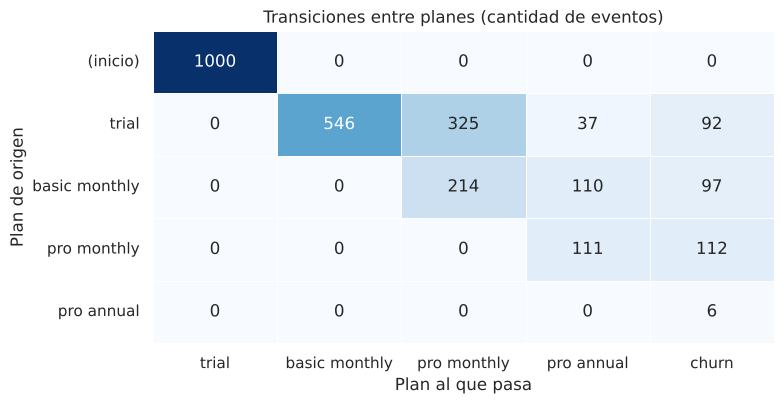

In [15]:
order = [TRIAL, BASIC, PRO_M, PRO_A, CHURN]
labels = [NAME[i] for i in order]
trans = pd.crosstab(w["prev_plan_id"].map(NAME).fillna("(inicio)"), w["plan_id"].map(NAME))
trans = trans.reindex(index=["(inicio)"] + labels[:-1], columns=labels, fill_value=0)

fig, ax = plt.subplots(figsize=(8, 4.2))
sns.heatmap(trans, annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=.5, ax=ax)
ax.set_title("Transiciones entre planes (cantidad de eventos)")
ax.set_xlabel("Plan al que pasa"); ax.set_ylabel("Plan de origen")
fig.tight_layout(); fig.savefig(FIG_DIR / "01_plan_transition_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

### Advertencias que condicionan el análisis
Dos patrones **no son errores** pero cambian cómo debemos interpretar la retención.

In [16]:
# ── A1. Planes anuales cuyo término de 365 días ya venció antes del corte, sin evento posterior ──
last_event = w.groupby("customer_id").tail(1).set_index("customer_id")
annual_all = w[w.plan_id == PRO_A].copy()
annual_all["term_end"] = annual_all["start_date"] + pd.Timedelta(days=365)
annual_all["ended_in_churn"] = annual_all["customer_id"].map(last_event["plan_id"] == CHURN)
expired = annual_all[annual_all["term_end"] <= OBSERVATION_END]
expired_no_event = expired[~expired["ended_in_churn"]]

rule("A1", "Planes anuales vencidos al corte sin evento de churn ni de renovación", len(expired_no_event), "advertencia",
     f"de {len(expired)} anuales vencidos al corte, {int(expired.ended_in_churn.sum())} cancelaron")
print(f"Anuales con término vencido al corte: {len(expired)}")
print(f"  · con churn registrado a los 365 días: {int(expired.ended_in_churn.sum())}")
print(f"  · SIN evento posterior (no sabemos si renovaron): {len(expired_no_event)}")

Anuales con término vencido al corte: 25
  · con churn registrado a los 365 días: 6
  · SIN evento posterior (no sabemos si renovaron): 19


Eventos que salen de un plan mensual (upgrade o churn): 644
Máximo de días entre el inicio de un plan mensual y el evento siguiente: 184
Clientes activos en plan mensual: 441 | llevan más de 184 días sin evento: 308 (70%)


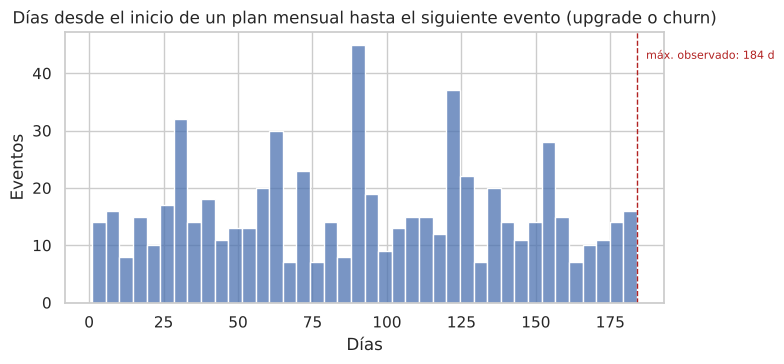

In [17]:
# ── A2. Tope temporal de los eventos que salen de un plan MENSUAL ──
# (se excluye el anual: su churn ocurre por diseño a los 365 días y distorsionaría el tope)
from_monthly = w[w["prev_plan_id"].isin([BASIC, PRO_M])]
max_gap_monthly = int(from_monthly["gap_days"].max())
print(f"Eventos que salen de un plan mensual (upgrade o churn): {len(from_monthly)}")
print(f"Máximo de días entre el inicio de un plan mensual y el evento siguiente: {max_gap_monthly}")

# Clientes que HOY están en un plan mensual (sin evento posterior) y llevan más días que ese tope sin ningún evento
active_monthly = last_event[last_event.plan_id.isin([BASIC, PRO_M])]
days_silent = (OBSERVATION_END - active_monthly["start_date"]).dt.days
beyond = int((days_silent > max_gap_monthly).sum())
print(f"Clientes activos en plan mensual: {len(active_monthly)} | llevan más de {max_gap_monthly} días sin evento: {beyond} "
      f"({beyond / len(active_monthly):.0%})")

rule("A2", f"Clientes activos en plan mensual sin evento hace más de {max_gap_monthly} días (tope histórico de los planes mensuales)",
     beyond, "advertencia", "Posible artefacto de generación sintética")

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.histplot(from_monthly["gap_days"], bins=40, color="#4C72B0", ax=ax)
ax.axvline(max_gap_monthly, color="firebrick", ls="--", lw=1)
ax.text(max_gap_monthly + 3, ax.get_ylim()[1] * .9, f"máx. observado: {max_gap_monthly} d", color="firebrick", fontsize=8)
ax.set_title("Días desde el inicio de un plan mensual hasta el siguiente evento (upgrade o churn)")
ax.set_xlabel("Días"); ax.set_ylabel("Eventos")
fig.tight_layout(); fig.savefig(FIG_DIR / "01_gap_days_monthly_plans.png", dpi=150, bbox_inches="tight")
plt.show()

### Cómo interpretar estas advertencias

- **A1 – Renovaciones anuales implícitas.** Un anual vencido sin evento posterior puede significar *renovación automática* (que el dataset no registra como evento)
  o un churn no registrado. **Supuesto adoptado:** se consideran **activos (renovados)** y quedan marcados con `annual_term_expired_no_event = True`
  para poder medir la sensibilidad del análisis.
- **A2 – Tope en los planes mensuales.** Ningún cliente cambia de plan o cancela pasado cierto umbral desde el inicio de un plan mensual, mientras que muchos clientes
  en plan mensual permanecen *activos* mucho más allá de ese umbral (ver porcentaje impreso arriba). En el histograma la distribución **se corta de forma abrupta**, sin la cola decreciente que sería esperable en datos reales. Esto sugiere que **el proceso que generó los datos no produce eventos tardíos**.
  **Consecuencia:** la retención de largo plazo en planes mensuales **no es informativa** (los sobrevivientes parecen "leales" simplemente porque el dataset no registra cancelaciones tardías).
  Los análisis de los notebooks siguientes lo tendrán en cuenta y esta limitación irá al README.

In [18]:
display(pd.DataFrame(rules).query("severidad == 'advertencia'")[["regla", "descripción", "violaciones", "nota"]])

,regla,descripción,violaciones,nota
8,A1,Planes anuales vencidos al corte sin evento de...,19,"de 25 anuales vencidos al corte, 6 cancelaron"
9,A2,Clientes activos en plan mensual sin evento ha...,308,Posible artefacto de generación sintética


## 9. Limpieza y preparación

**Resumen del diagnóstico:** los datos originales están formalmente limpios (sin nulos reales, sin duplicados, sin huérfanos, fechas válidas, reglas críticas cumplidas).
Por lo tanto **no se elimina ninguna fila ni se corrige ningún valor**. La "limpieza" consiste en **tipificar, ordenar, enriquecer y documentar**.

| # | Decisión | Alternativa descartada | Motivo |
|---|---|---|---|
| D1 | Conservar las 2.650 filas | Filtrar eventos "sospechosos" | No hay violaciones críticas; borrar sesgaría el análisis |
| D2 | `price` del *churn* → `0.0` + `is_paid_plan` | Dejar `NaN` | Evita propagar `NaN` en sumas de ingresos |
| D3 | Anuales vencidos sin evento → activos (flag aparte) | Contarlos como churn | No hay evidencia de cancelación; el flag permite análisis de sensibilidad |
| D4 | Corte de observación = última fecha registrada | Usar la fecha actual | Con fecha actual todos parecerían activos años sin evidencia |
| D5 | Duración de planes vigentes calculada hasta el corte y marcada como **censurada** | Tratarla como duración final | Es una cota inferior, no un dato completo |
| D6 | Moneda sin especificar → columna `price` sin símbolo | Asumir USD/EUR | La fuente no declara la moneda |

In [19]:
transform_log = []
def log(step, action, rows_in, rows_out, why):
    transform_log.append({"paso": step, "acción": action, "filas_entrada": rows_in, "filas_salida": rows_out, "motivo": why})

n0 = len(subs)
log("T1", "Tipificar columnas (int64 / datetime64 / float64) con formato de fecha explícito", n0, len(subs),
    "Evitar fechas como texto y errores de día/mes")

# T2 · orden cronológico por cliente (estable → no altera empates; no hay empates, ver R6)
events = subs.sort_values(["customer_id", "start_date"], kind="stable").reset_index(drop=True)
assert events[["customer_id", "plan_id", "start_date"]].equals(subs.reset_index(drop=True)), "El orden original difería"
log("T2", "Ordenar por (customer_id, start_date)", n0, len(events), "Las features de secuencia dependen del orden; el origen ya estaba ordenado (verificado)")

# T3 · incorporar el catálogo de planes
events = events.merge(plans, on="plan_id", how="left", validate="m:1")
log("T3", "Unir con `plans` (m:1)", n0, len(events), "Traer nombre y precio del plan a cada evento")

# T4 · nulo estructural de price
events["is_paid_plan"] = events["price"].fillna(0) > 0
events["price"] = events["price"].fillna(0.0)
log("T4", "price NaN → 0.0 (plan churn) y flag is_paid_plan", len(events), len(events), "Decisión D2")

# T5 · features de secuencia por cliente
g = events.groupby("customer_id")
events["event_seq"] = g.cumcount() + 1
events["prev_plan_id"] = g["plan_id"].shift(1).astype("Int64")
events["prev_plan_name"] = g["plan_name"].shift(1)
events["next_start_date"] = g["start_date"].shift(-1)

events["is_first_event"] = events["event_seq"].eq(1)
events["is_last_event"] = events["next_start_date"].isna()
events["is_churn_event"] = events["plan_name"].eq("churn")
events["is_conversion"] = events["is_paid_plan"] & events["prev_plan_name"].eq("trial")       # trial → plan pago
events["is_upgrade"] = events["is_paid_plan"] & events["prev_plan_id"].isin([BASIC, PRO_M]) & (events["plan_id"] > events["prev_plan_id"])
log("T5", "Features de secuencia: event_seq, prev/next, flags (primer/último evento, churn, conversión, upgrade)", len(events), len(events),
    "Base para cohortes, funnel y análisis de transiciones")

# T6 · duración del plan (días hasta el siguiente evento; si es el último, hasta el corte → censurada)
end = events["next_start_date"].fillna(OBSERVATION_END)
days = (end - events["start_date"]).dt.days.astype("Int64")
events["days_in_plan"] = days.mask(events["is_churn_event"])                 # churn no es un plan con duración
events["duration_is_censored"] = events["is_last_event"] & ~events["is_churn_event"]
log("T6", "days_in_plan y duration_is_censored", len(events), len(events), "Decisión D5")

display(pd.DataFrame(transform_log))

,paso,acción,filas_entrada,filas_salida,motivo
0,T1,Tipificar columnas (int64 / datetime64 / float...,2650,2650,Evitar fechas como texto y errores de día/mes
1,T2,"Ordenar por (customer_id, start_date)",2650,2650,Las features de secuencia dependen del orden; ...
2,T3,Unir con `plans` (m:1),2650,2650,Traer nombre y precio del plan a cada evento
3,T4,price NaN → 0.0 (plan churn) y flag is_paid_plan,2650,2650,Decisión D2
4,T5,"Features de secuencia: event_seq, prev/next, f...",2650,2650,"Base para cohortes, funnel y análisis de trans..."
5,T6,days_in_plan y duration_is_censored,2650,2650,Decisión D5


## 10. Dataset consolidado

Construyo dos vistas a partir del mismo origen:

- **`events_clean`** — grano *evento* (2.650 filas): ideal para funnel, transiciones e ingresos por plan.
- **`customers_clean`** — grano *cliente* (1.000 filas): ideal para cohortes, retención, churn y segmentación.

In [20]:
ev = events  # alias corto

# Piezas del dataset de clientes (cada una indexada por customer_id)
trial = ev.loc[ev["plan_name"] == "trial", ["customer_id", "start_date"]].rename(columns={"start_date": "trial_start_date"})

paid = ev[ev["is_paid_plan"]]
first_paid = (paid.drop_duplicates("customer_id", keep="first")
                  [["customer_id", "plan_name", "start_date"]]
                  .rename(columns={"plan_name": "first_paid_plan", "start_date": "first_paid_date"}))
last_paid = (paid.drop_duplicates("customer_id", keep="last")[["customer_id", "plan_name"]]
                 .rename(columns={"plan_name": "last_paid_plan"}))

churn = (ev[ev["is_churn_event"]][["customer_id", "start_date", "prev_plan_name"]]
           .rename(columns={"start_date": "churn_date", "prev_plan_name": "churned_from_plan"}))

last_ev = ev[ev["is_last_event"]][["customer_id", "plan_name", "start_date"]].rename(
    columns={"plan_name": "last_event_plan", "start_date": "last_event_date"})

agg = ev.groupby("customer_id").agg(
    n_events=("event_seq", "size"),
    n_upgrades=("is_upgrade", "sum"),
    plan_path=("plan_name", lambda s: " > ".join(s)),
).reset_index()

customers = (trial.merge(first_paid, on="customer_id", how="left")
                  .merge(last_paid, on="customer_id", how="left")
                  .merge(churn, on="customer_id", how="left")
                  .merge(last_ev, on="customer_id", how="left", validate="1:1")
                  .merge(agg, on="customer_id", validate="1:1"))

# Variables derivadas
customers["cohort_month"] = customers["trial_start_date"].dt.strftime("%Y-%m")          # cohorte = mes de inicio del trial
customers["converted_to_paid"] = customers["first_paid_date"].notna()
customers["days_trial_to_paid"] = (customers["first_paid_date"] - customers["trial_start_date"]).dt.days.astype("Int64")
customers["is_churned"] = customers["churn_date"].notna()
customers["ever_upgraded"] = customers["n_upgrades"] > 0
customers["current_plan"] = np.where(customers["is_churned"], "churned", customers["last_event_plan"])
customers["observation_end"] = OBSERVATION_END

end_date = customers["churn_date"].fillna(OBSERVATION_END)                               # fin de la observación del cliente
customers["follow_up_days"] = (end_date - customers["trial_start_date"]).dt.days         # tiempo observado desde el trial
customers["paid_days"] = (end_date - customers["first_paid_date"]).dt.days.astype("Int64")  # tiempo como cliente pago (NA si nunca pagó)
customers["is_censored"] = ~customers["is_churned"]                                       # activo al corte → no sabemos su desenlace

# Bandera de la advertencia A1 (decisión D3)
exp_ids = set(expired_no_event["customer_id"])
customers["annual_term_expired_no_event"] = customers["customer_id"].isin(exp_ids)

customers = customers.sort_values("customer_id").reset_index(drop=True)
print("customers:", customers.shape)
customers.head(8)

customers: (1000, 23)


,customer_id,trial_start_date,first_paid_plan,first_paid_date,last_paid_plan,churn_date,churned_from_plan,last_event_plan,last_event_date,n_events,n_upgrades,plan_path,cohort_month,converted_to_paid,days_trial_to_paid,is_churned,ever_upgraded,current_plan,observation_end,follow_up_days,paid_days,is_censored,annual_term_expired_no_event
0,1,2020-08-01,basic monthly,2020-08-08,basic monthly,NaT,<NA>,basic monthly,2020-08-08,2,0,trial > basic monthly,2020-08,True,7,False,False,basic monthly,2021-04-30,272,265,True,False
1,2,2020-09-20,pro annual,2020-09-27,pro annual,NaT,<NA>,pro annual,2020-09-27,2,0,trial > pro annual,2020-09,True,7,False,False,pro annual,2021-04-30,222,215,True,False
2,3,2020-01-13,basic monthly,2020-01-20,basic monthly,NaT,<NA>,basic monthly,2020-01-20,2,0,trial > basic monthly,2020-01,True,7,False,False,basic monthly,2021-04-30,473,466,True,False
3,4,2020-01-17,basic monthly,2020-01-24,basic monthly,2020-04-21,basic monthly,churn,2020-04-21,3,0,trial > basic monthly > churn,2020-01,True,7,True,False,churned,2021-04-30,95,88,False,False
4,5,2020-08-03,basic monthly,2020-08-10,basic monthly,NaT,<NA>,basic monthly,2020-08-10,2,0,trial > basic monthly,2020-08,True,7,False,False,basic monthly,2021-04-30,270,263,True,False
5,6,2020-12-23,basic monthly,2020-12-30,basic monthly,2021-02-26,basic monthly,churn,2021-02-26,3,0,trial > basic monthly > churn,2020-12,True,7,True,False,churned,2021-04-30,65,58,False,False
6,7,2020-02-05,basic monthly,2020-02-12,pro monthly,NaT,<NA>,pro monthly,2020-05-22,3,1,trial > basic monthly > pro monthly,2020-02,True,7,False,True,pro monthly,2021-04-30,450,443,True,False
7,8,2020-06-11,basic monthly,2020-06-18,pro monthly,NaT,<NA>,pro monthly,2020-08-03,3,1,trial > basic monthly > pro monthly,2020-06,True,7,False,True,pro monthly,2021-04-30,323,316,True,False


### Validación del dataset consolidado con **chequeos independientes**
Los totales se recalculan por un camino distinto (conjuntos construidos directamente sobre la tabla original tipada `subs`, sin usar ninguna columna derivada).

In [21]:
# ── Camino independiente: conjuntos de clientes desde `subs` (datos originales) ──
churn_ids = set(subs.loc[subs["plan_id"] == CHURN, "customer_id"])
paid_ids = set(subs.loc[subs["plan_id"].isin([BASIC, PRO_M, PRO_A]), "customer_id"])
trial_only_churn_ids = churn_ids - paid_ids

# 1) Estructura
assert len(customers) == subs["customer_id"].nunique() == 1000
assert customers["customer_id"].is_unique
assert len(events) == len(subs) == 2650
assert customers["n_events"].sum() == len(subs)

# 2) Totales vs. método independiente
assert set(customers.loc[customers["is_churned"], "customer_id"]) == churn_ids
assert set(customers.loc[customers["converted_to_paid"], "customer_id"]) == paid_ids
assert set(customers.loc[customers["is_churned"] & ~customers["converted_to_paid"], "customer_id"]) == trial_only_churn_ids

# 3) Coherencia interna
assert (customers["plan_path"].str.count(">") + 1).eq(customers["n_events"]).all()   # el path reconstruye la cantidad de eventos
assert customers["trial_start_date"].lt(customers["first_paid_date"].fillna(pd.Timestamp.max)).all()
assert customers.loc[customers["is_churned"], "churn_date"].ge(customers.loc[customers["is_churned"], "trial_start_date"]).all()
assert (customers["follow_up_days"] >= 7).all()
assert customers["is_censored"].sum() + customers["is_churned"].sum() == 1000

# 4) Cifras publicadas del caso de estudio (eventos desde 2021-01-01 por plan_id): 8 / 60 / 63 / 71
published_2021 = {BASIC: 8, PRO_M: 60, PRO_A: 63, CHURN: 71}
calc_2021 = events.loc[events["start_date"] >= "2021-01-01", "plan_id"].value_counts().to_dict()
assert calc_2021 == published_2021, calc_2021

# 5) Cifras de la Fase 1 (evaluación de datasets)
assert (customers["converted_to_paid"].sum(), customers["is_churned"].sum(),
        len(trial_only_churn_ids), customers["is_censored"].sum()) == (908, 307, 92, 693)

print("✔ Todos los chequeos del dataset consolidado pasan.")
print(f"   Convertidos a pago: {customers['converted_to_paid'].sum()} | Churn: {customers['is_churned'].sum()} "
      f"(de los cuales {len(trial_only_churn_ids)} directo desde el trial) | Activos al corte: {customers['is_censored'].sum()}")

✔ Todos los chequeos del dataset consolidado pasan.
   Convertidos a pago: 908 | Churn: 307 (de los cuales 92 directo desde el trial) | Activos al corte: 693


### Tamaño de las cohortes
Cohorte = mes de inicio del trial. Como los trials sólo empiezan durante 2020 pero la observación llega a abril 2021,
**cada cohorte tiene una ventana de seguimiento distinta** (la de enero 2020 es mucho más larga que la de diciembre).
Esto es lo que se llama *censura* y condiciona la comparación de cohortes en el notebook 02.

cohort_month,2020-01,2020-02,2020-03,2020-04,2020-05,2020-06,2020-07,2020-08,2020-09,2020-10,2020-11,2020-12
clientes,88,68,94,81,88,79,89,88,87,79,75,84
seguimiento_máx_días,485,454,425,394,364,333,303,272,241,211,180,149


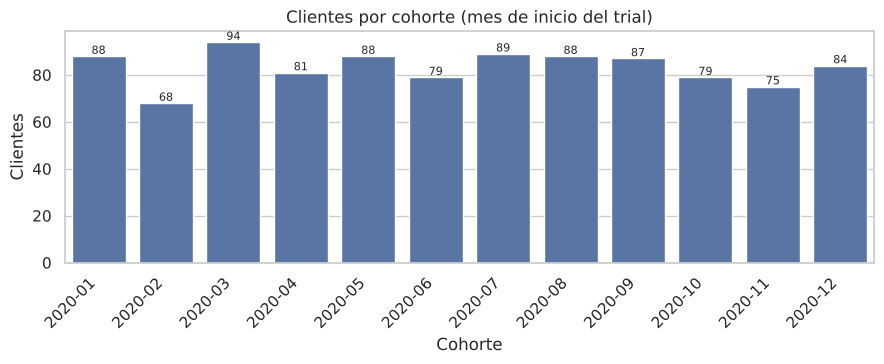

In [22]:
cohorts = (customers.groupby("cohort_month")
                    .agg(clientes=("customer_id", "size"),
                         seguimiento_máx_días=("follow_up_days", "max"))
                    .reset_index())
display(cohorts.set_index("cohort_month").T)
assert cohorts["clientes"].sum() == 1000 and cohorts["cohort_month"].nunique() == 12

fig, ax = plt.subplots(figsize=(9, 3.8))
sns.barplot(data=cohorts, x="cohort_month", y="clientes", color="#4C72B0", ax=ax)
for i, v in enumerate(cohorts["clientes"]):
    ax.text(i, v + 1, str(v), ha="center", fontsize=8)
ax.set_title("Clientes por cohorte (mes de inicio del trial)")
ax.set_xlabel("Cohorte"); ax.set_ylabel("Clientes")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
fig.tight_layout(); fig.savefig(FIG_DIR / "01_cohort_sizes.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Guardado y verificación de lectura

In [23]:
# Orden de columnas legible
event_cols = ["customer_id", "event_seq", "plan_id", "plan_name", "price", "is_paid_plan", "start_date",
              "next_start_date", "days_in_plan", "duration_is_censored", "prev_plan_id", "prev_plan_name",
              "is_first_event", "is_last_event", "is_churn_event", "is_conversion", "is_upgrade"]
customer_cols = ["customer_id", "trial_start_date", "cohort_month", "converted_to_paid", "first_paid_plan",
                 "first_paid_date", "days_trial_to_paid", "last_paid_plan", "current_plan", "is_churned",
                 "churn_date", "churned_from_plan", "n_events", "n_upgrades", "ever_upgraded", "plan_path",
                 "last_event_plan", "last_event_date", "observation_end", "follow_up_days", "paid_days",
                 "is_censored", "annual_term_expired_no_event"]

events_clean = events[event_cols].copy()
customers_clean = customers[customer_cols].copy()

events_path = PROC_DIR / "foodie_fi_events_clean.csv"
customers_path = PROC_DIR / "foodie_fi_customers_clean.csv"
events_clean.to_csv(events_path, index=False)         # fechas en ISO, punto decimal
customers_clean.to_csv(customers_path, index=False)

# Releer desde disco y comparar con lo que está en memoria (garantiza que lo guardado es lo validado)
ev_back = pd.read_csv(events_path, parse_dates=["start_date", "next_start_date"])
cu_back = pd.read_csv(customers_path, parse_dates=["trial_start_date", "first_paid_date", "churn_date",
                                                   "last_event_date", "observation_end"])
pd.testing.assert_frame_equal(ev_back, events_clean, check_dtype=False)
pd.testing.assert_frame_equal(cu_back, customers_clean, check_dtype=False)
print(f"✔ {events_path.relative_to(PROJECT_ROOT)}     {events_clean.shape}")
print(f"✔ {customers_path.relative_to(PROJECT_ROOT)}  {customers_clean.shape}")
print("✔ Lectura de vuelta idéntica a lo validado en memoria.")

✔ data/processed/foodie_fi_events_clean.csv     (2650, 17)
✔ data/processed/foodie_fi_customers_clean.csv  (1000, 23)
✔ Lectura de vuelta idéntica a lo validado en memoria.


## 12. Verificación de integridad y conclusiones

In [24]:
# Los archivos originales NO deben haber cambiado
raw_hashes_after = {p.name: sha256(p) for p in sorted(RAW_DIR.glob("*.csv"))}
assert raw_hashes_after == raw_hashes_before
print("✔ Datos originales intactos (hashes SHA-256 idénticos a los del inicio).")

display(pd.DataFrame(rules)[["regla", "descripción", "violaciones", "severidad"]])

✔ Datos originales intactos (hashes SHA-256 idénticos a los del inicio).


,regla,descripción,violaciones,severidad
0,R1,El primer evento de cada cliente es el trial,0,crítica
1,R2,Cada cliente tiene un único trial,0,crítica
2,R3,El evento posterior al trial ocurre a los 7 días,0,crítica
3,R4,'churn' es siempre el último evento del cliente,0,crítica
4,R5,Ningún evento ocurre después de un 'churn',0,crítica
5,R6,Fechas estrictamente crecientes por cliente (s...,0,crítica
6,R7,Sólo transiciones válidas: upgrades o cancelac...,0,crítica
7,R8,Churn desde 'pro annual' ocurre exactamente a ...,0,crítica
8,A1,Planes anuales vencidos al corte sin evento de...,19,advertencia
9,A2,Clientes activos en plan mensual sin evento ha...,308,advertencia


### Conclusiones de la etapa

**Calidad de los datos**
- Sin nulos reales, sin duplicados, sin huérfanos y con fechas válidas (parseo verificado ida y vuelta).
- Todas las **reglas de negocio críticas** se cumplen: el ciclo de vida es consistente (trial de 7 días → plan → posible churn terminal, sin downgrades).
- Las cifras del caso de estudio publicado (8 / 60 / 63 / 71 eventos en 2021) se reproducen exactamente.

**Advertencias que heredan los notebooks siguientes**
1. **Censura desigual:** los trials sólo empiezan en 2020 pero la observación llega a abril de 2021 → cada cohorte tiene una ventana de seguimiento distinta. Las comparaciones de retención deben hacerse a **ventanas equivalentes**.
2. **Anuales vencidos sin evento (A1):** tratados como activos; se mantiene el flag `annual_term_expired_no_event` para análisis de sensibilidad.
3. **Tope entre eventos (A2):** la retención de largo plazo en planes mensuales **no es informativa** porque el dataset no registra eventos tardíos.
4. **Datos sintéticos, sin atributos demográficos ni de canal y con ingresos derivados de precios de lista** (limitaciones de la Fase 1).

### Qué sigue
**`02_eda_funnel_and_behavior.ipynb`** — análisis exploratorio del comportamiento: embudo trial → plan → churn, mezcla de planes, caminos más frecuentes y tiempos hasta upgrade o cancelación.